# Lab: Practical Application of Transpose Convolution — worked study copy

Answers prepared for revision with AI assistance. IBM / Skills Network source notices and embedded instructor explanations are retained. This is not a course submission.

Code completion and execution are tracked separately in the [solution progress report](../../../docs/SOLUTION_PROGRESS.md). Training may require a separate environment, external data, compute or provider credentials.

[Original reference](../../../courses/03-keras-and-tensorflow/notebooks/lab-practical-application-of-transpose-convolution.ipynb) · [Course notes](../../../courses/03-keras-and-tensorflow/README.md)

**BOUNDED SMOKE RUN:** seed 42; CSVs sampled to at most 5,000 rows; one grid setting with two folds; training budgets capped; DataLoaders limited to 12 batches. These outputs are execution checks, not full-run model evaluations. Bundled TensorFlow datasets use 512 training / 256 test examples; fit inputs use at most 512 examples or eight dataset batches.

In [1]:
import os, itertools, random
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['TF_NUM_INTEROP_THREADS'] = '1'
os.environ['TF_NUM_INTRAOP_THREADS'] = '1'
import numpy as np
np.random.seed(42)
random.seed(42)
import pandas as pd
_read_csv = pd.read_csv
def _bounded_csv(*args, **kwargs):
    data = _read_csv(*args, **kwargs)
    return data.sample(n=5000,random_state=42) if len(data)>5000 else data
pd.read_csv = _bounded_csv
from sklearn.model_selection import GridSearchCV
_grid_fit = GridSearchCV.fit
def _bounded_grid(self, *args, **kwargs):
    grids = self.param_grid if isinstance(self.param_grid,list) else [self.param_grid]
    self.param_grid = [{k:list(v)[:1] for k,v in grid.items()} for grid in grids[:1]]
    self.cv = 2
    self.n_jobs = 1
    self.verbose = 0
    return _grid_fit(self,*args,**kwargs)
GridSearchCV.fit = _bounded_grid
try:
    import torch
except ImportError:
    torch = None
if torch is not None:
    torch.manual_seed(42)
    torch.set_num_threads(1)
    _loader_iter = torch.utils.data.DataLoader.__iter__
    def _bounded_loader(self):
        return itertools.islice(_loader_iter(self),12)
    torch.utils.data.DataLoader.__iter__ = _bounded_loader
import tensorflow as tf
tf.random.set_seed(42)
for _dataset in [tf.keras.datasets.mnist,tf.keras.datasets.fashion_mnist,tf.keras.datasets.cifar10]:
    _original_load = _dataset.load_data
    def _small_load(*args,_load=_original_load,**kwargs):
        (x,y),(xt,yt) = _load(*args,**kwargs)
        return (x[:512],y[:512]),(xt[:256],yt[:256])
    _dataset.load_data = _small_load
_keras_fit = tf.keras.Model.fit
def _small_fit(self,*args,**kwargs):
    args = list(args)
    def _limit(value):
        if isinstance(value,(np.ndarray,pd.DataFrame,pd.Series)):return value[:512]
        if isinstance(value,(tuple,list)) and value and all(isinstance(x,np.ndarray) for x in value):return type(value)(x[:512] for x in value)
        if isinstance(value,tf.data.Dataset):return value.take(8)
        return value
    for i in range(min(2,len(args))):args[i]=_limit(args[i])
    for key in ['x','y','validation_data']:
        if key in kwargs:kwargs[key]=_limit(kwargs[key])
    kwargs['epochs']=min(2,kwargs.get('epochs',2))
    data=args[0] if args else kwargs.get('x')
    if hasattr(data,'class_indices'):
        kwargs['steps_per_epoch']=min(2,len(data))
        if hasattr(kwargs.get('validation_data'),'class_indices'):
            kwargs['validation_steps']=min(2,len(kwargs['validation_data']))
    return _keras_fit(self,*args,**kwargs)
tf.keras.Model.fit = _small_fit


Matplotlib is building the font cache; this may take a moment.


<img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/BQm_EV6i0_j80CQZ8vcLvw/SN-web-lightmode.png" width=300 height=300 />


## Lab: Practical Application of Transpose Convolution  

**Estimated time needed: 30 minutes**

This lab will guide you through creating, training, and evaluating models that use transpose convolution layers for tasks such as image reconstruction. 

##### Learning objectives: 

By the end of this lab, you will: 

- Apply transpose convolution in practical scenarios using Keras.  

- Create, compile, train, and evaluate the model 

- Visualize the results  

##### Prerequisites: 

- Basic understanding of Python programming 

- Familiarity with convolutional neural network (CNN) concepts 

- Keras and TensorFlow installed 




#### Steps: 
**Step 1: Import Necessary Libraries**

Before you start, make sure to import the required libraries: TensorFlow and Keras. Keras is included within TensorFlow as `tensorflow.keras`. 


In [2]:
import warnings
warnings.simplefilter('ignore')
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, Conv2DTranspose, UpSampling2D
import numpy as np
import matplotlib.pyplot as plt

**Explanation:**

 `tensorflow` is the main library for machine learning in Python. 

  `Model, Input, Conv2D, and Conv2DTranspose` are used to create and manipulate the layers in your model. 

  `numpy` and `matplotlib` are used for data manipulation and visualization. 

 
**Step 2: Define the Input Layer**

You need to define the input shape for your model. For simplicity, let's assume you are working with an input image of size 28x28 with 1 channel (grayscale). 

 


In [3]:
input_layer = Input(shape=(28, 28, 1))

**Explanation:**

`Input(shape=(28, 28, 1))` creates an input layer that expects 28x28 grayscale images.


**Step 3: Add convolutional and transpose convolutional layers**

You will add a convolutional layer to extract features, followed by a transpose convolution layer to reconstruct the image. 


In [4]:
conv_layer = Conv2D(filters=32, kernel_size=(3, 3), activation='relu', padding='same')(input_layer)
transpose_conv_layer = Conv2DTranspose(filters=1, kernel_size=(3, 3), activation='sigmoid', padding='same')(conv_layer)

**Explanation:**

`Conv2D(filters=32, kernel_size=(3, 3), activation='relu', padding='same')` creates a convolution layer with 32 filters. 

`Conv2DTranspose(filters=1, kernel_size=(3, 3), activation='sigmoid', padding='same')` creates a transpose convolution layer for reconstructing the image. 

**Step 4: Create the Model**

Now, you will create the model by specifying the input and output layers.


In [5]:
model = Model(inputs=input_layer, outputs=transpose_conv_layer)

**Explanation:**

`Model(inputs=input_layer, outputs=transpose_conv_layer)` creates a Keras model that connects the input layer to the output layer through the convolutional and transpose convolutional layers.  

**Step 5: Compile the Model**

Before training the model, you need to compile it. You will specify the loss function, optimizer, and evaluation metrics. 


In [6]:
model.compile(optimizer='adam', loss='mean_squared_error')

**Explanation:**

- optimizer=`adam` specifies the Adam optimizer. 

- loss=`mean_squared_error` specifies the mean squared error loss function.  


**Step 6: Train the Model**

You can now train the model on some training data. For this example, let's assume X_train is our training input data.


In [7]:
X_train = np.random.rand(1000, 28, 28, 1)
y_train = X_train
history = model.fit(X_train, y_train, epochs=2, batch_size=32, validation_split=0.2)

Epoch 1/2


 1/13 ━━━━━━━━━━━━━━━━━━━━ 2s 217ms/step - loss: 0.0868

10/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0851  

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0843 - val_loss: 0.0759


Epoch 2/2


 1/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0753

10/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0735 

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0727 - val_loss: 0.0633


**Explanation:**

- X_train is a placeholder for your actual training data. 

- y_train is the same as X_train for image reconstruction. 

- model.fit trains the model for a specified number of epochs and batch size.

  
**Step 7: Evaluate the Model**

After training, you can evaluate the model on test data to see how well it performs. 


In [8]:
X_test = np.random.rand(200, 28, 28, 1)
y_test = X_test
loss = model.evaluate(X_test, y_test)
print(f'Test loss: {loss}')

1/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0633

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0634


Test loss: 0.06336762756109238


**Explanation:**

`X_test` and `y_test` are placeholders for your actual test data. 

`model.evaluate` computes the loss of the model on test data. . 

**Step 8: Visualize the Results**

To better understand the model's performance, let's visualize some reconstructed images.  


1/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


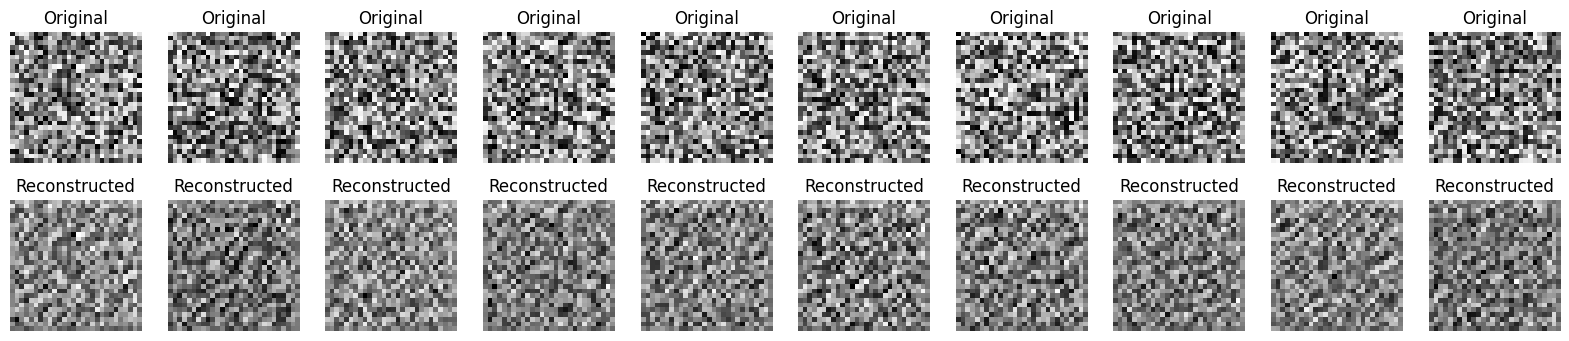

In [9]:
y_pred = model.predict(X_test)
n = 10
plt.figure(figsize=(20, 4))
for i in range(n):
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')
    plt.title('Original')
    plt.axis('off')
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(y_pred[i].reshape(28, 28), cmap='gray')
    plt.title('Reconstructed')
    plt.axis('off')
plt.show()

**Explanation:**

`model.predict` generates predictions for the test data. 

`plt.imshow` visualizes the original and reconstructed images side by side for comparison. 


### Practice exercises


#### Exercise 1: Experiment with Different Kernel Sizes 

**Objective:** Understand the impact of different kernel sizes on the model's performance. 

**Instructions:**
1. Modify the kernel size of the `Conv2D` and `Conv2DTranspose` layers. 
2. Recompile, train, and evaluate the model. 
3. Observe and record the differences in performance.


In [10]:
def reconstruction_variant(kernel_size=3, dropout=0.0, activation='relu', decoder_activation='sigmoid'):
    inputs_local = Input(shape=(28, 28, 1))
    hidden = Conv2D(32, kernel_size, activation=activation, padding='same')(inputs_local)
    if dropout:
        hidden = tf.keras.layers.Dropout(dropout)(hidden)
    output_local = Conv2DTranspose(1, kernel_size, activation=decoder_activation, padding='same')(hidden)
    variant = Model(inputs_local, output_local)
    variant.compile(optimizer='adam', loss='mean_squared_error')
    return variant
kernel_results = {}
for size in [3, 5, 7]:
    variant = reconstruction_variant(kernel_size=size)
    variant.fit(X_train, y_train, epochs=2, batch_size=32, validation_split=0.2, verbose=0)
    kernel_results[size] = float(variant.evaluate(X_test, y_test, verbose=0))
print('Kernel size / held-out reconstruction MSE:', kernel_results)

Kernel size / held-out reconstruction MSE: {3: 0.06793677061796188, 5: 0.041662007570266724, 7: 0.027425797656178474}


<details>
<summary>Click here for solution</summary> </br>

```python
from tensorflow.keras.layers import Dropout, Conv2D, Conv2DTranspose, Input
from tensorflow.keras.models import Model

# Define the input layer
input_layer = Input(shape=(28, 28, 1))

# Add convolutional and transpose convolutional layers with different kernel sizes
conv_layer = Conv2D(filters=32, kernel_size=(5, 5), activation='relu', padding='same')(input_layer)
transpose_conv_layer = Conv2DTranspose(filters=1, kernel_size=(5, 5), activation='sigmoid', padding='same')(conv_layer)

# Create the model
model = Model(inputs=input_layer, outputs=transpose_conv_layer)

# Compile the model
model.compile(optimizer='adam', loss='mean_squared_error')

# Train the model
history = model.fit(X_train, y_train, epochs=10, batch_size=32, validation_split=0.2)

# Evaluate the model
loss = model.evaluate(X_test, y_test)
print(f'Test loss: {loss}')


#### Exercise 2: Add Dropout Layers

**Objective:** Add dropout layers to prevent overfitting.

**Instructions:**
1. Add dropout layers after the convolutional layer. 
2. Set the dropout rate to 0.5.
3. Recompile, train, and evaluate the model.


In [11]:
dropout_model = reconstruction_variant(dropout=0.5)
dropout_model.fit(X_train, y_train, epochs=2, batch_size=32, validation_split=0.2)
print('Dropout test loss:', dropout_model.evaluate(X_test, y_test, verbose=0))

Epoch 1/2


 1/13 ━━━━━━━━━━━━━━━━━━━━ 2s 232ms/step - loss: 0.0865

 7/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0855  

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0845

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0843 - val_loss: 0.0762


Epoch 2/2


 1/13 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0764

 7/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0752 

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0741

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0739 - val_loss: 0.0641


Dropout test loss: 0.0642225444316864


<details>
<summary>Click here for solution</summary> </br>

```python
from tensorflow.keras.layers import Dropout, Conv2D, Conv2DTranspose, Input
from tensorflow.keras.models import Model

# Define the input layer
input_layer = Input(shape=(28, 28, 1))

# Add convolutional, dropout, and transpose convolutional layers
conv_layer = Conv2D(filters=32, kernel_size=(3, 3), activation='relu', padding='same')(input_layer)
dropout_layer = Dropout(0.5)(conv_layer)
transpose_conv_layer = Conv2DTranspose(filters=1, kernel_size=(3, 3), activation='sigmoid', padding='same')(dropout_layer)

# Create the model
model = Model(inputs=input_layer, outputs=transpose_conv_layer)

# Compile the model
model.compile(optimizer='adam', loss='mean_squared_error')

# Train the model
history = model.fit(X_train, y_train, epochs=10, batch_size=32, validation_split=0.2)

# Evaluate the model
loss = model.evaluate(X_test, y_test)
print(f'Test loss: {loss}')


#### Exercise 3: Use Different Activation Functions 

**Objective:** Experiment with different activation functions and observe their impact on model performance. 

**Instructions:**
1. Change the activation function of the convolutional and transpose convolutional layers to `tanh`. 
2. Recompile, train, and evaluate the model.


In [12]:
tanh_model = reconstruction_variant(activation='tanh', decoder_activation='tanh')
tanh_model.fit(X_train, y_train, epochs=2, batch_size=32, validation_split=0.2)
print('Tanh test loss:', tanh_model.evaluate(X_test, y_test, verbose=0))

Epoch 1/2


 1/13 ━━━━━━━━━━━━━━━━━━━━ 2s 207ms/step - loss: 0.1841

10/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1199  

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.1090 - val_loss: 0.0616


Epoch 2/2


 1/13 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0611

10/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0559 

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0535 - val_loss: 0.0333


Tanh test loss: 0.03340895473957062


<details>
<summary>Click here for solution</summary> </br>

```python

from tensorflow.keras.layers import Conv2D, Conv2DTranspose, Input
from tensorflow.keras.models import Model

# Define the input layer
input_layer = Input(shape=(28, 28, 1))

# Add convolutional and transpose convolutional layers with different activation functions
conv_layer = Conv2D(filters=32, kernel_size=(3, 3), activation='tanh', padding='same')(input_layer)
transpose_conv_layer = Conv2DTranspose(filters=1, kernel_size=(3, 3), activation='tanh', padding='same')(conv_layer)

# Create the model
model = Model(inputs=input_layer, outputs=transpose_conv_layer)

# Compile the model
model.compile(optimizer='adam', loss='mean_squared_error')

# Train the model
history = model.fit(X_train, y_train, epochs=10, batch_size=32, validation_split=0.2)

# Evaluate the model
loss = model.evaluate(X_test, y_test)
print(f'Test loss: {loss}')



### Conclusion:

By completing this lab, you have successfully created, trained, and evaluated a simple neural network model using transpose convolution for image reconstruction. This exercise provided hands-on experience with Keras and practical applications of transpose convolution layers. Continue experimenting with different architectures and datasets to deepen your understanding and skills in deep learning with Keras. 


Copyright © IBM Corporation. All rights reserved.
